# 29F — Independent Grouping Validation

This notebook evaluates whether the analyzer correctly groups related Java maintainability findings. Independent reviewer judgments are required before computing quality metrics.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
root = next(p for p in [root, *root.parents] if (p / 'Code Cleanliness' / 'evaluation').is_dir())
folder = root / 'Code Cleanliness' / 'evaluation' / 'results' / 'final_evaluation' / 'grouping'
df = pd.read_csv(folder / 'pairwise_independent_review.csv')
print('Total pairs:', len(df))
display(df['system_same_group'].value_counts().sort_index())


Total pairs: 160


system_same_group
0    80
1    80
Name: count, dtype: int64

In [2]:
# Flag generated-code candidates; never silently discard them.
patterns = r'(?i)(internal.*parser|\.antlr|generated|/target/|\\target\\)'
df['generated_code_candidate'] = (
    df['finding_a'].fillna('').str.contains(patterns, regex=True)
    | df['finding_b'].fillna('').str.contains(patterns, regex=True)
)
print('Generated-code candidates:')
display(pd.crosstab(df['system_same_group'], df['generated_code_candidate']))
display(df[['finding_a', 'finding_b', 'system_same_group', 'generated_code_candidate']].head(10))


Generated-code candidates:


C:\Users\sithu\AppData\Local\Temp\ipykernel_23268\4271317040.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['finding_a'].fillna('').str.contains(patterns, regex=True)
C:\Users\sithu\AppData\Local\Temp\ipykernel_23268\4271317040.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  | df['finding_b'].fillna('').str.contains(patterns, regex=True)


generated_code_candidate,False,True
system_same_group,,
0,4,76
1,0,80


,finding_a,finding_b,system_same_group,generated_code_candidate
0,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
1,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
2,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
3,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
4,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
5,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
6,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
7,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
8,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True
9,C:\4th Year\Research Work\Implementation Stage...,C:\4th Year\Research Work\Implementation Stage...,1,True


## Independent review

Inspect each selected pair's source code and maintainability context. Set `gold_same_issue` to 1 only when both findings represent the same underlying maintainability problem; otherwise set it to 0. Record the rationale in `reviewer_notes`. Leave uncertain cases unlabeled.

Do not substitute the analyzer's `system_same_group` prediction for an independent reference judgment.


In [3]:
# Inspect the four candidates not flagged as generated code.
normal = df.loc[
    ~df["generated_code_candidate"],
    ["finding_a", "finding_b", "system_same_group"]
]

for i, row in normal.iterrows():
    print(f"\nPAIR {i}")
    print("Finding A:", row["finding_a"])
    print("Finding B:", row["finding_b"])
    print("Analyzer same group:", row["system_same_group"])


PAIR 87
Finding A: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\datasets\processed\mlcq_29f\source_batch\mlcq_java_repo\3700666\CanalEntry.java:12152:com.alibaba.otter.canal.protocol.CanalEntry.Pair.internalGetFieldAccessorTable():DUPLICATED_LOGIC:38211c2b972a8f7993ea9038cd80404b7f5b21e590378cb50805929ba9ed4f63
Finding B: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\datasets\processed\mlcq_29f\source_batch\mlcq_java_repo\3700666\CanalEntry.java:6:12839:com.alibaba.otter.canal.protocol.CanalEntry:LARGE_CLASS
Analyzer same group: 0

PAIR 106
Finding A: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\datasets\processed\mlcq_29f\source_batch\mlcq_java_repo\3700666\CanalEntry.java:4370:com.alibaba.otter.canal.protocol.CanalEntry.Column.hasIsKey():DUPLICATED_LOGIC:57025438790340a6921f0753c4b3fb09ed2edc2b5a6b7117bbb68b0ab415cb22
Finding B: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Clea

In [4]:

# 29F — Grouping pilot: prepare independent review pairs
# Uses actual analyzer findings; does not invent ground-truth labels.

from pathlib import Path
from itertools import combinations
import json
import csv
import pandas as pd
from IPython.display import display

repo = Path(r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361")
folder = repo / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation" / "grouping"
evidence = json.loads((folder / "pilot_analyzer_evidence.json").read_text(encoding="utf-8"))

groups = evidence["ranked_groups"]
findings = {}

# Collect distinct findings and their analyzer-assigned group memberships.
for group in groups:
    group_id = str(group["group_id"])
    for finding in group.get("findings", []):
        fid = str(finding["finding_id"])
        if fid not in findings:
            findings[fid] = {"data": finding, "groups": set()}
        findings[fid]["groups"].add(group_id)

def source_context(finding, radius=4):
    """Read a few Java source lines around the reported finding."""
    path = Path(str(finding.get("source_file") or ""))
    line = finding.get("start_line")

    if not path.is_file() or not isinstance(line, int):
        return "Source context unavailable"

    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    if not 1 <= line <= len(lines):
        return "Line number unavailable"

    lo = max(1, line - radius)
    hi = min(len(lines), line + radius)
    return "\n".join(f"{i}: {lines[i-1]}" for i in range(lo, hi + 1))

rows = []

for (id_a, a), (id_b, b) in combinations(findings.items(), 2):
    fa, fb = a["data"], b["data"]

    rows.append({
        "finding_a_id": id_a,
        "finding_b_id": id_b,
        "concern_a": fa.get("concern", ""),
        "concern_b": fb.get("concern", ""),
        "symbol_a": fa.get("symbol", ""),
        "symbol_b": fb.get("symbol", ""),
        "description_a": fa.get("description", ""),
        "description_b": fb.get("description", ""),
        "source_a": fa.get("source_file", ""),
        "source_b": fb.get("source_file", ""),
        "context_a": source_context(fa),
        "context_b": source_context(fb),
        "system_same_group": int(bool(a["groups"] & b["groups"])),
        "gold_same_issue": "",
        "reviewer_notes": ""
    })

review = pd.DataFrame(rows)

assert len(findings) >= 2, "Not enough distinct findings for pair review."
assert len(review) == len(findings) * (len(findings) - 1) // 2

output = folder / "pilot_pairwise_review.csv"
review.to_csv(output, index=False, encoding="utf-8-sig")

print("Distinct findings:", len(findings))
print("Candidate pairs:", len(review))
print("Analyzer predictions:")
display(review["system_same_group"].value_counts().sort_index())
display(review[[
    "concern_a", "symbol_a",
    "concern_b", "symbol_b",
    "system_same_group"
]])

print("Saved:", output)
print("Independent ground-truth labels: PENDING")


Distinct findings: 6
Candidate pairs: 15
Analyzer predictions:


system_same_group
0    8
1    7
Name: count, dtype: int64

,concern_a,symbol_a,concern_b,symbol_b,system_same_group
0,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,1
1,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handlePayment...,1
2,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),LARGE_CLASS,com.iluwatar.commander.Commander,1
3,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.caching.CacheStore.get(String),0
4,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.caching.LruCache.contains(String),0
5,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handlePayment...,1
6,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,LARGE_CLASS,com.iluwatar.commander.Commander,1
7,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,DUPLICATED_LOGIC,com.iluwatar.caching.CacheStore.get(String),0
8,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,DUPLICATED_LOGIC,com.iluwatar.caching.LruCache.contains(String),0
9,DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handlePayment...,LARGE_CLASS,com.iluwatar.commander.Commander,1


Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pilot_pairwise_review.csv
Independent ground-truth labels: PENDING


In [1]:
# Recover actual Java source context for the 15 review pairs.
# This does not assign ground-truth labels.

from pathlib import Path
import pandas as pd
import re
from IPython.display import display

source_root = Path(
    r"C:\4th Year\Research Work\Prototype\Research-Prototype"
    r"\src\codeQuality\testData"
)

folder = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
    r"\Code Cleanliness\evaluation\results\final_evaluation\grouping"
)

review = pd.read_csv(folder / "pilot_pairwise_review.csv")

def get_context(source, finding_id, radius=12):
    path = source_root / str(source).replace("/", "\\")

    if not path.is_file():
        return f"FILE NOT FOUND: {path}"

    # Extract the reported source line from the finding identifier.
    match = re.search(r"\.java:(\d+)", str(finding_id))

    if not match:
        return "LINE NUMBER NOT FOUND"

    line = int(match.group(1))
    lines = path.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines()

    lo = max(1, line - radius)
    hi = min(len(lines), line + radius)

    return "\n".join(
        f"{i}: {lines[i-1]}"
        for i in range(lo, hi + 1)
    )

review["context_a"] = review.apply(
    lambda r: get_context(r["source_a"], r["finding_a_id"]),
    axis=1
)

review["context_b"] = review.apply(
    lambda r: get_context(r["source_b"], r["finding_b_id"]),
    axis=1
)

# Blind review sheet: remove analyzer prediction while judging.
blind = review.drop(columns=["system_same_group"])

output = folder / "pilot_blind_review.csv"
blind.to_csv(output, index=False, encoding="utf-8-sig")

print("Pairs:", len(blind))
print("Source A available:",
      (~blind["context_a"].str.startswith(
          ("FILE NOT FOUND", "LINE NUMBER NOT FOUND")
      )).sum())
print("Source B available:",
      (~blind["context_b"].str.startswith(
          ("FILE NOT FOUND", "LINE NUMBER NOT FOUND")
      )).sum())

print("Saved:", output)

display(blind[[
    "concern_a", "symbol_a",
    "concern_b", "symbol_b",
    "gold_same_issue"
]].head())

Pairs: 15
Source A available: 15
Source B available: 15
Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pilot_blind_review.csv


,concern_a,symbol_a,concern_b,symbol_b,gold_same_issue
0,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handleSuccess...,NaN
1,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.commander.Commander.handlePayment...,NaN
2,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),LARGE_CLASS,com.iluwatar.commander.Commander,NaN
3,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.caching.CacheStore.get(String),NaN
4,HIGH_COMPLEXITY,Commander.updateQueue(QueueTask),DUPLICATED_LOGIC,com.iluwatar.caching.LruCache.contains(String),NaN


In [ ]:

# GROUPING VALIDATION — FINAL SCORING
# Run ONLY this cell. Do not click "Run All".

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

root = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
)
folder = (
    root / "Code Cleanliness" / "evaluation" /
    "results" / "final_evaluation"
)
grouping = folder / "grouping"
graphs = folder / "graphs"
graphs.mkdir(parents=True, exist_ok=True)

# Read the review you completed.
gold = pd.read_csv(grouping / "pilot_blind_review.csv")
system = pd.read_csv(grouping / "pilot_pairwise_review.csv")

# Convert manually entered labels to numeric values.
gold["gold_same_issue"] = pd.to_numeric(
    gold["gold_same_issue"], errors="coerce"
)

# Match by finding IDs rather than CSV row order.
data = gold.merge(
    system[[
        "finding_a_id", "finding_b_id", "system_same_group"
    ]],
    on=["finding_a_id", "finding_b_id"],
    validate="one_to_one"
)

valid = data[data["gold_same_issue"].isin([0, 1])].copy()

print("Total pairs:", len(data))
print("Reviewed pairs:", len(valid))
print("Unreviewed pairs:", len(data) - len(valid))

if len(valid) == 0:
    raise ValueError(
        "No reviewer labels found. Check that the edited "
        "pilot_blind_review.csv was saved."
    )

y_true = valid["gold_same_issue"].astype(int)
y_pred = valid["system_same_group"].astype(int)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

metrics = pd.DataFrame([{
    "reviewed_pairs": len(valid),
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "reviewer_positive_pairs": int(y_true.sum()),
    "system_positive_pairs": int(y_pred.sum())
}])

display(metrics)

metrics.to_csv(
    grouping / "pilot_grouping_metrics.csv", index=False
)

valid.to_csv(
    grouping / "pilot_scored_pairs.csv", index=False
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Different", "Same"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("Maintainability Grouping — Independent Pilot")
fig.tight_layout()

fig.savefig(
    graphs / "grouping_pilot_confusion_matrix.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("\nGROUPING VALIDATION COMPLETE")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))
print("Results saved successfully.")


In [5]:
import pandas as pd

p = folder / "grouping" / "pilot_blind_review.csv"
check = pd.read_csv(p)

print("File:", p)
print("Total pairs:", len(check))
print("Labels entered:", check["gold_same_issue"].notna().sum())

display(check[[
    "symbol_a",
    "symbol_b",
    "gold_same_issue",
    "reviewer_notes"
]])

File: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pilot_blind_review.csv
Total pairs: 15
Labels entered: 0


,symbol_a,symbol_b,gold_same_issue,reviewer_notes
0,Commander.updateQueue(QueueTask),com.iluwatar.commander.Commander.handleSuccess...,NaN,NaN
1,Commander.updateQueue(QueueTask),com.iluwatar.commander.Commander.handlePayment...,NaN,NaN
2,Commander.updateQueue(QueueTask),com.iluwatar.commander.Commander,NaN,NaN
3,Commander.updateQueue(QueueTask),com.iluwatar.caching.CacheStore.get(String),NaN,NaN
4,Commander.updateQueue(QueueTask),com.iluwatar.caching.LruCache.contains(String),NaN,NaN
5,com.iluwatar.commander.Commander.handleSuccess...,com.iluwatar.commander.Commander.handlePayment...,NaN,NaN
6,com.iluwatar.commander.Commander.handleSuccess...,com.iluwatar.commander.Commander,NaN,NaN
7,com.iluwatar.commander.Commander.handleSuccess...,com.iluwatar.caching.CacheStore.get(String),NaN,NaN
8,com.iluwatar.commander.Commander.handleSuccess...,com.iluwatar.caching.LruCache.contains(String),NaN,NaN
9,com.iluwatar.commander.Commander.handlePayment...,com.iluwatar.commander.Commander,NaN,NaN


,evaluation_type,total_pairs,assessed_pairs,uncertain_pairs,precision_vs_ai_assessment,recall_vs_ai_assessment,f1_vs_ai_assessment,independent_human_validation
0,AI-assisted preliminary agreement,15,14,1,0.166667,1.0,0.285714,NOT COMPLETED


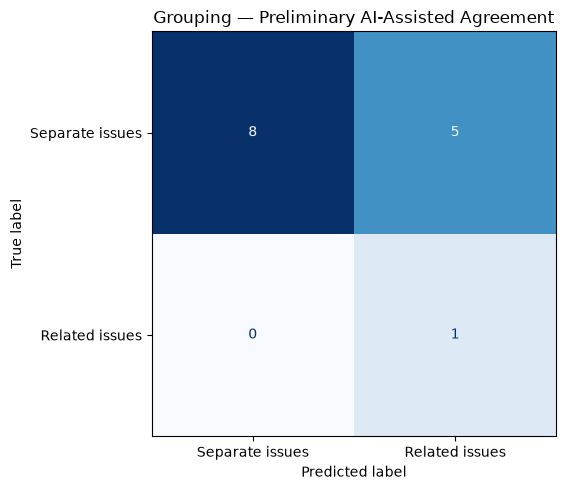

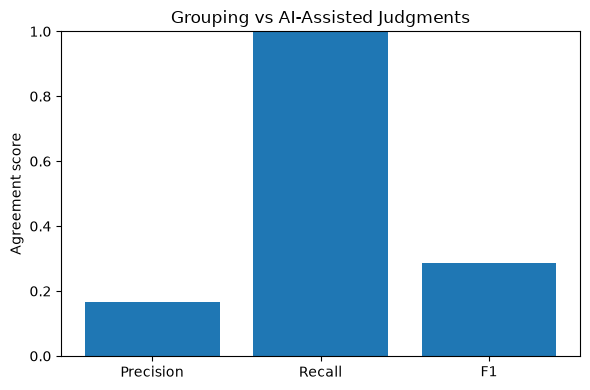

SAVED:
C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pilot_ai_assessment.csv
C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pilot_ai_assessment_metrics.csv
Graphs: 2
Human-independent grouping validation: PENDING


In [6]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

root = Path(r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361")
base = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
grouping = base / "grouping"
graphs = base / "graphs"
graphs.mkdir(parents=True, exist_ok=True)

# Read actual analyzer predictions.
df = pd.read_csv(grouping / "pilot_pairwise_review.csv")

assert len(df) == 15, "Unexpected pilot sample size."

# AI-assisted judgments based on supplied source snippets.
# None = insufficient evidence for a confident judgment.
# These are NOT independent human ground-truth annotations.
assessments = {
    0: (0, "Queue complexity and duplicated error handling are distinct concerns."),
    1: (0, "Queue complexity and duplicated error handling are distinct concerns."),
    2: (None, "Complexity contributes to class maintenance, but joint remediation is uncertain."),
    3: (0, "Unrelated queue and caching concerns."),
    4: (0, "Unrelated queue and caching concerns."),
    5: (1, "Both error-handling methods share similar control flow and retry logic."),
    6: (0, "Duplicated error handling and class size are different underlying concerns."),
    7: (0, "Unrelated error-handling and cache-delegation functionality."),
    8: (0, "Unrelated error-handling and cache-lookup functionality."),
    9: (0, "Duplicated error handling and class size are different underlying concerns."),
    10: (0, "Unrelated error-handling and cache-delegation functionality."),
    11: (0, "Unrelated error-handling and cache-lookup functionality."),
    12: (0, "Class size and caching are unrelated concerns."),
    13: (0, "Class size and caching are unrelated concerns."),
    14: (0, "Two short delegation/lookup methods have different behavior; similar structure alone is insufficient.")
}

df["ai_assessment"] = [assessments[i][0] for i in range(len(df))]
df["ai_rationale"] = [assessments[i][1] for i in range(len(df))]
df["assessment_type"] = "AI_ASSISTED_PRELIMINARY_NOT_INDEPENDENT"

assessment_file = grouping / "pilot_ai_assessment.csv"
df.to_csv(assessment_file, index=False, encoding="utf-8-sig")

scored = df.dropna(subset=["ai_assessment"]).copy()
y_true = scored["ai_assessment"].astype(int)
y_pred = scored["system_same_group"].astype(int)

p = precision_score(y_true, y_pred, zero_division=0)
r = recall_score(y_true, y_pred, zero_division=0)
f = f1_score(y_true, y_pred, zero_division=0)

summary = pd.DataFrame([{
    "evaluation_type": "AI-assisted preliminary agreement",
    "total_pairs": len(df),
    "assessed_pairs": len(scored),
    "uncertain_pairs": len(df) - len(scored),
    "precision_vs_ai_assessment": p,
    "recall_vs_ai_assessment": r,
    "f1_vs_ai_assessment": f,
    "independent_human_validation": "NOT COMPLETED"
}])

display(summary)
summary.to_csv(
    grouping / "pilot_ai_assessment_metrics.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_true, y_pred, labels=[0, 1]),
    display_labels=["Separate issues", "Related issues"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Grouping — Preliminary AI-Assisted Agreement")
fig.tight_layout()
fig.savefig(
    graphs / "grouping_ai_assisted_confusion_matrix.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Precision", "Recall", "F1"], [p, r, f])
ax.set_ylim(0, 1)
ax.set_ylabel("Agreement score")
ax.set_title("Grouping vs AI-Assisted Judgments")
fig.tight_layout()
fig.savefig(
    graphs / "grouping_ai_assisted_metrics.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("SAVED:")
print(assessment_file)
print(grouping / "pilot_ai_assessment_metrics.csv")
print("Graphs: 2")
print("Human-independent grouping validation: PENDING")
